# ROI_processing

In [40]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import seaborn as sns

import hotspot

In [42]:
# Technology 1: Xenium
sdata = sd.read_zarr("/media/sergio/Meninges/troutpy/rois/xenium_mscolon_5k/data_processed.zarr")
results = sdata["xrna_metadata"].var

In [22]:
adata = sdata["table"]
hs = hotspot.Hotspot(adata, layer_key="raw", model="danb", latent_obsm_key="X_pca", umi_counts_obs_key="n_counts")

hs.create_knn_graph(weighted_graph=False, n_neighbors=10)
hs_results = hs.compute_autocorrelations()
hs_genes = hs_results.loc[hs_results.FDR < 0.001].index  # Select genes
local_correlations = hs.compute_local_correlations(hs_genes, jobs=4)  # jobs for parallelization

# calculate modules
modules = hs.create_modules(min_gene_threshold=6, core_only=True, fdr_threshold=0.0005)
module_scores = hs.calculate_module_scores()

100%|██████████| 979/979 [00:00<00:00, 1885.27it/s]


Computing pair-wise local correlation on 321 features...


100%|██████████| 51360/51360 [00:04<00:00, 11348.61it/s]


Computing scores for 13 modules...


100%|██████████| 13/13 [00:00<00:00, 89.35it/s]


In [ ]:
hs.plot_local_correlations(vmax=10, vmin=-10)

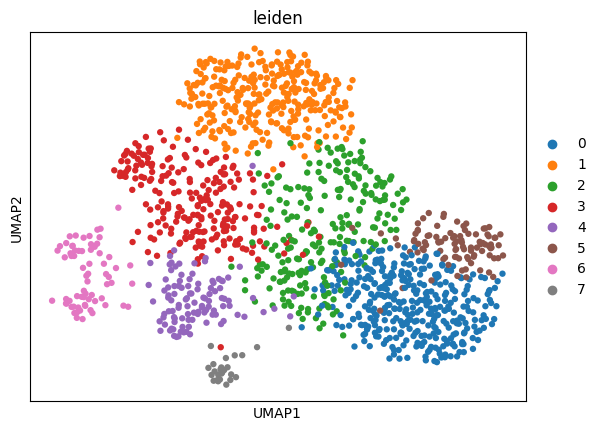

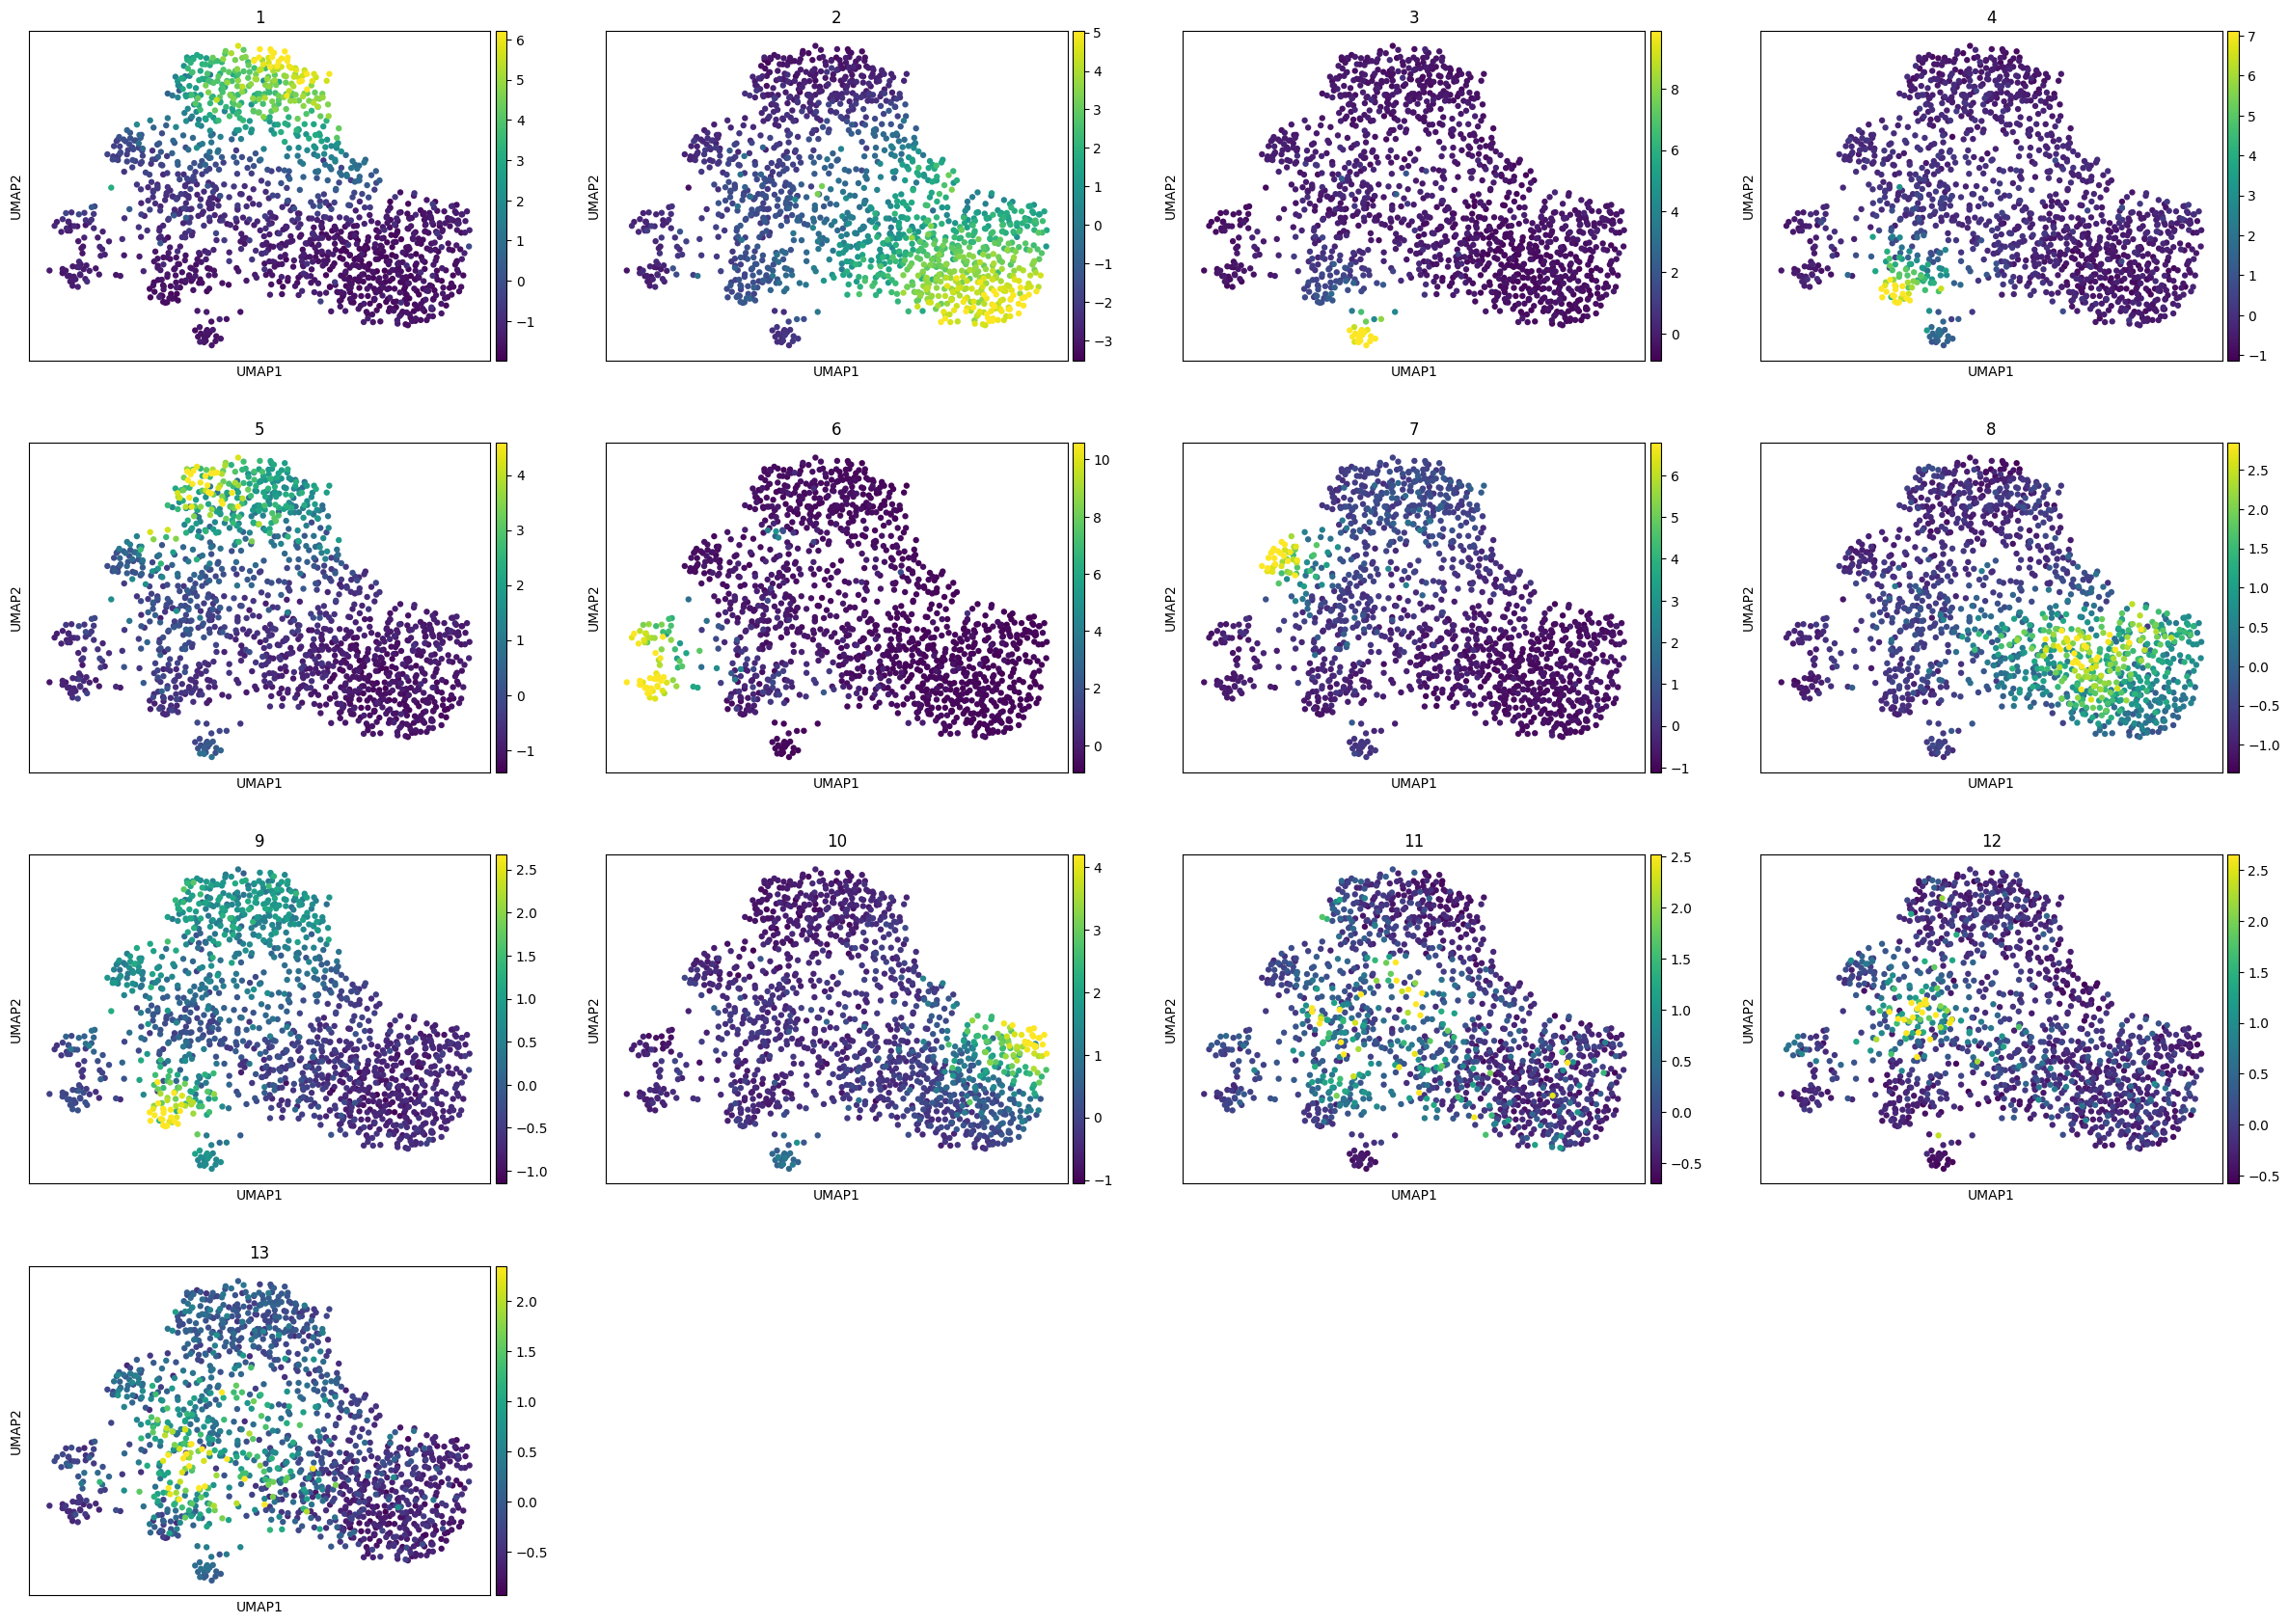

In [25]:
adata_scores = sc.AnnData(module_scores, obs=adata.obs)
adata_scores.obsm["X_umap"] = adata.obsm["X_umap"]
adata_scores.obsm["X_pca"] = adata.obsm["X_pca"]
sc.pl.umap(adata, color="leiden")
sc.pl.umap(adata_scores, color=adata_scores.var.index, vmax="p99")

In [26]:
dictmod = dict(zip(modules.index, modules.values))
results["module"] = results.index.map(dictmod)

In [27]:
import matplotlib.pyplot as plt


def annotate_top_bottom(
    df, metric1, metric2, n=5, label_col=None, figsize=(8, 6), scatter_kwargs=None, annotate_kwargs=None, title_tag=""
):
    """
    Scatter-plot df[metric1] vs df[metric2] and annotate the top/bottom n points
    along each axis.

    Parameters
    ----------
    df : pandas.DataFrame
        The data.
    metric1 : str
        Column name for the x-axis metric.
    metric2 : str
        Column name for the y-axis metric.
    n : int, optional (default=5)
        Number of top and bottom points to label per metric.
    label_col : str or None, optional (default=None)
        Column name containing the labels. If None, uses df.index.
    figsize : tuple, optional (default=(8, 6))
        Figure size.
    scatter_kwargs : dict or None
        Extra kwargs passed to plt.scatter().
    annotate_kwargs : dict or None
        Extra kwargs passed to plt.annotate().
    Title tag: str, optional (default='')

    Returns
    -------
    fig, ax : matplotlib.figure.Figure, matplotlib.axes.Axes
        The figure and axes objects.
    """
    # Prepare labels
    df_plot = df.copy()
    if label_col is None:
        df_plot["__idx_label"] = df_plot.index.astype(str)
        label_col = "__idx_label"

    # Plot
    fig, ax = plt.subplots(figsize=figsize)
    sc_kwargs = {} if scatter_kwargs is None else scatter_kwargs
    ax.scatter(df_plot[metric1], df_plot[metric2], **sc_kwargs)
    ax.set_xlabel(metric1)
    ax.set_ylabel(metric2)
    ax.set_title(f"{title_tag}: {metric1} vs {metric2}")

    # Find indices to annotate
    top1 = df_plot.nlargest(n, metric1).index
    bot1 = df_plot.nsmallest(n, metric1).index
    top2 = df_plot.nlargest(n, metric2).index
    bot2 = df_plot.nsmallest(n, metric2).index
    to_annotate = set(top1) | set(bot1) | set(top2) | set(bot2)

    # Annotate
    ann_kwargs = dict(xytext=(5, 5), textcoords="offset points", ha="left", va="bottom", fontsize=8, alpha=0.8)
    if annotate_kwargs:
        ann_kwargs.update(annotate_kwargs)

    for idx in to_annotate:
        x = df_plot.loc[idx, metric1]
        y = df_plot.loc[idx, metric2]
        label = df_plot.loc[idx, label_col]
        ax.annotate(label, xy=(x, y), **ann_kwargs)

    fig.tight_layout()
    return fig, ax

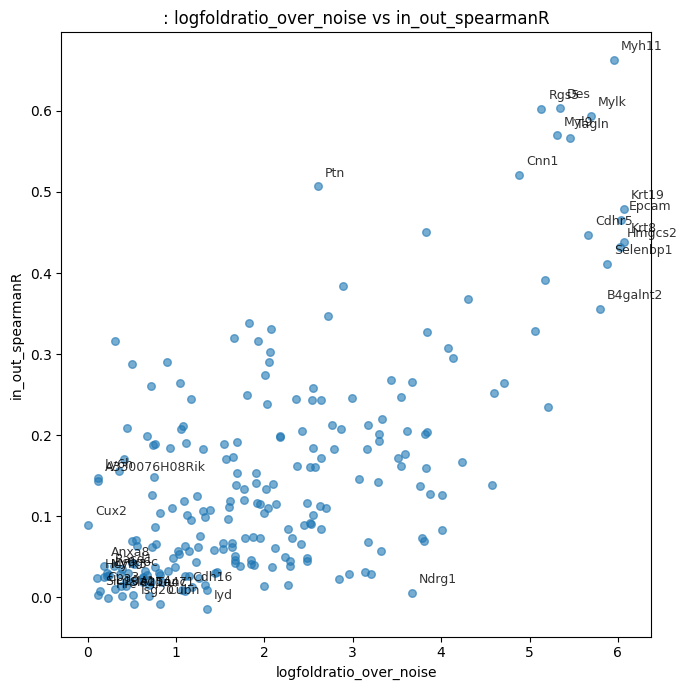

In [43]:
results2 = results[results["logfoldratio_over_noise"] > 0]
fig, ax = annotate_top_bottom(
    df=results2,
    metric1="logfoldratio_over_noise",
    metric2="in_out_spearmanR",
    n=10,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    figsize=(7, 7),
)
plt.show()

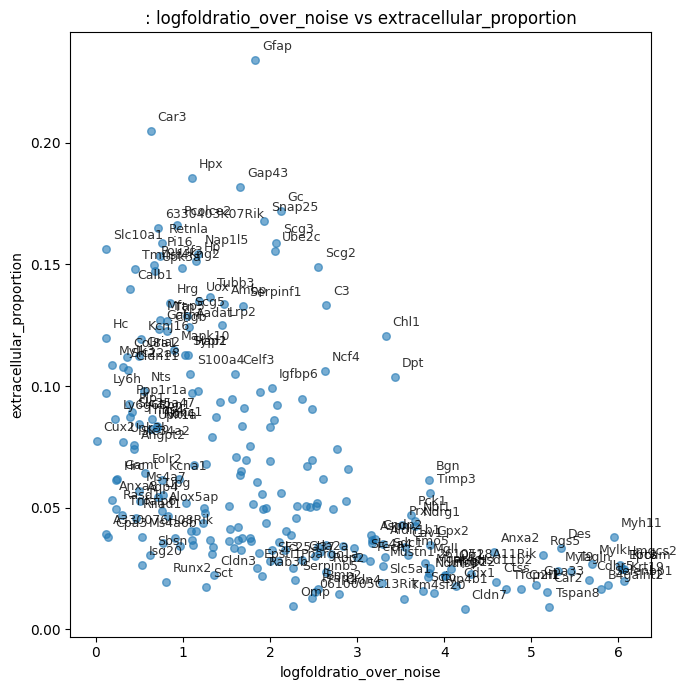

In [46]:
fig, ax = annotate_top_bottom(
    df=results2,
    metric1="logfoldratio_over_noise",
    metric2="extracellular_proportion",
    n=50,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    figsize=(7, 7),
)
plt.show()

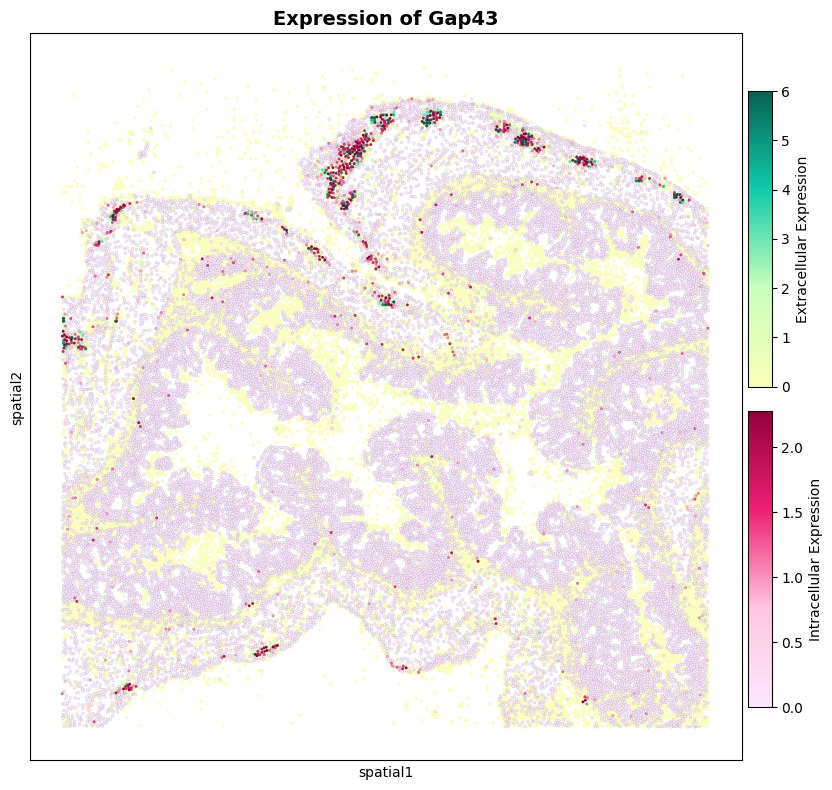

In [50]:
# spatial maps-in out
g2 = "Gap43"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10)

In [ ]:
for g, i in results.groupby("module"):
    if g > -1:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="extracellular_proportion",
            n=5,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 9, "color": "black"},
            title_tag=g,
            figsize=(4, 4),
        )
        plt.show()

In [ ]:
for g, i in results.groupby("module"):
    if g > -1:
        print(g)
        # Suppose `results` is your DataFrame and you have a column 'gene' with names:
        fig, ax = annotate_top_bottom(
            df=i,
            metric1="logfoldratio_over_noise",
            metric2="in_out_spearmanR",
            n=5,
            scatter_kwargs={"alpha": 0.6, "s": 30},
            annotate_kwargs={"fontsize": 9, "color": "black"},
            title_tag=g,
            figsize=(4, 4),
        )
        plt.show()

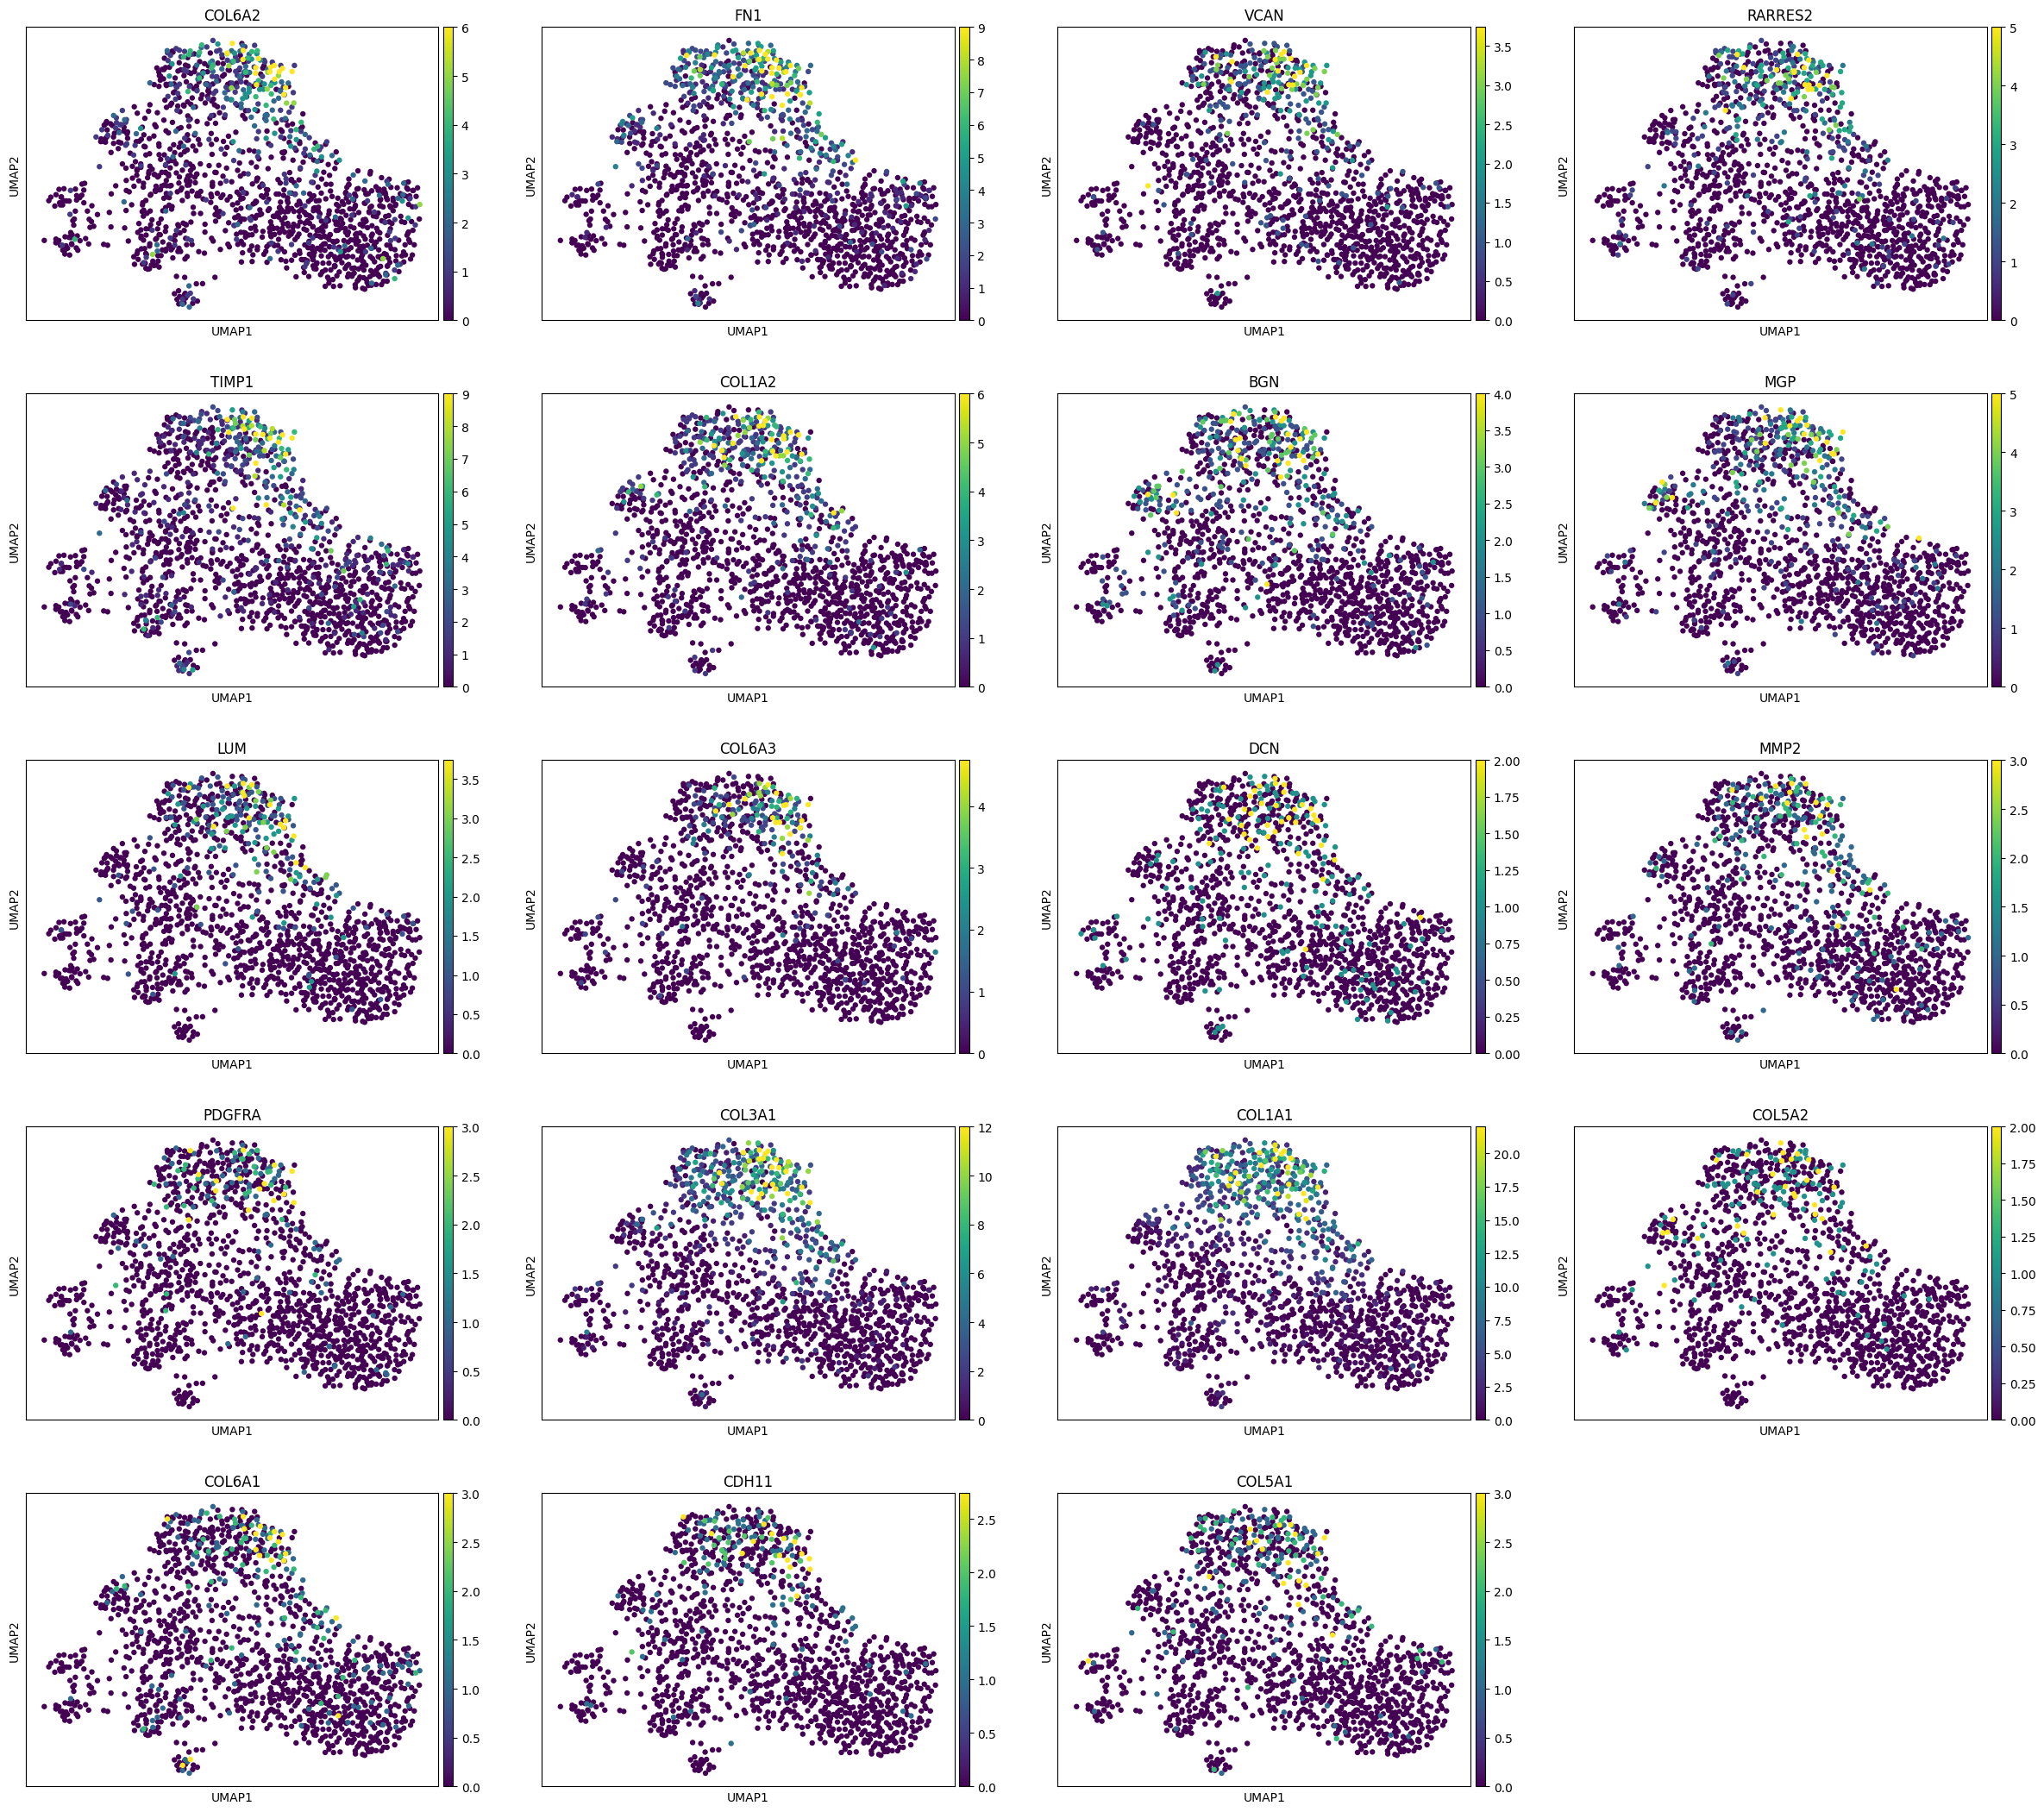

Index(['COL6A2', 'FN1', 'VCAN', 'RARRES2', 'TIMP1', 'COL1A2', 'BGN', 'MGP',
       'LUM', 'COL6A3', 'DCN', 'MMP2', 'PDGFRA', 'COL3A1', 'COL1A1', 'COL5A2',
       'COL6A1', 'CDH11', 'COL5A1'],
      dtype='object')


In [30]:
import pandas as pd

mods_df = pd.DataFrame(modules).sort_values(by="Module")
genes = mods_df[mods_df["Module"] == 1].index
sc.pl.umap(adata, color=genes, vmax="p99")
print(genes)

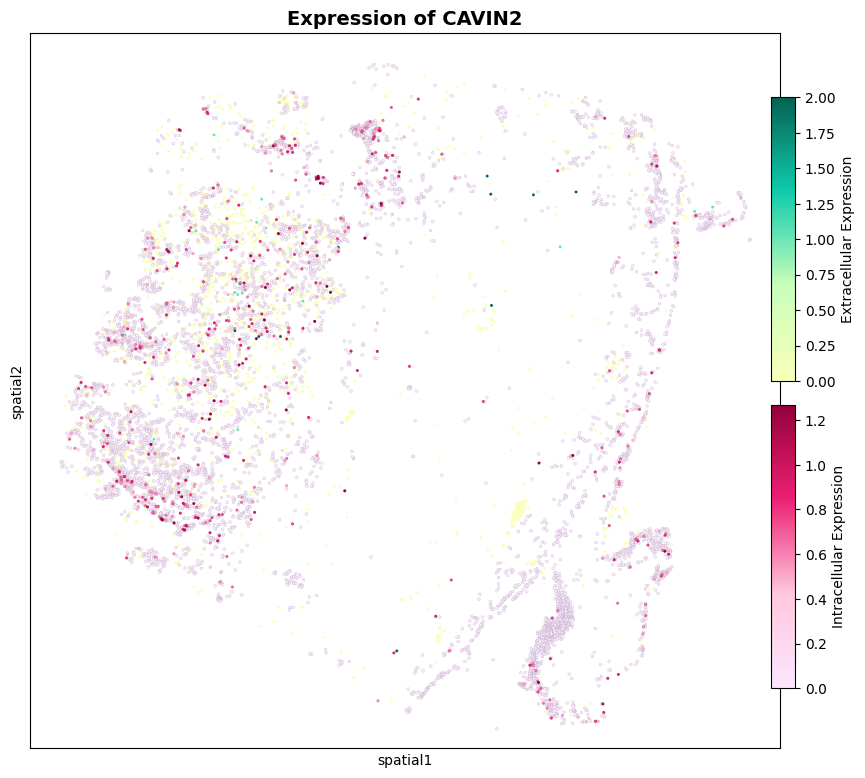

In [ ]:
g2 = "CAVIN2"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=40, spot_size_extra=40)

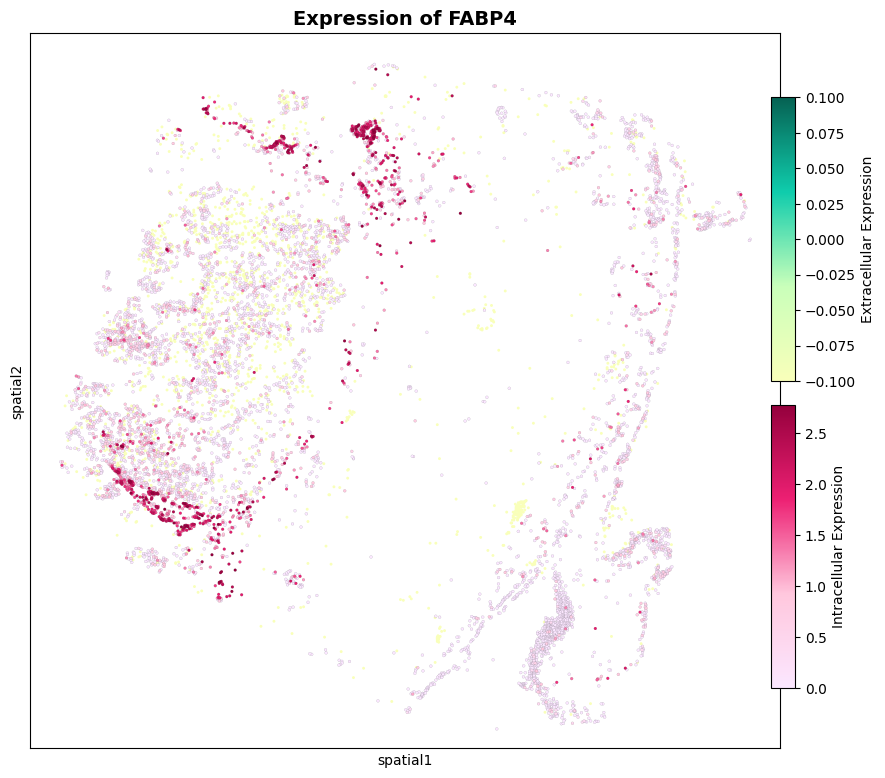

In [18]:
g2 = "FABP4"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=40, spot_size_extra=40)

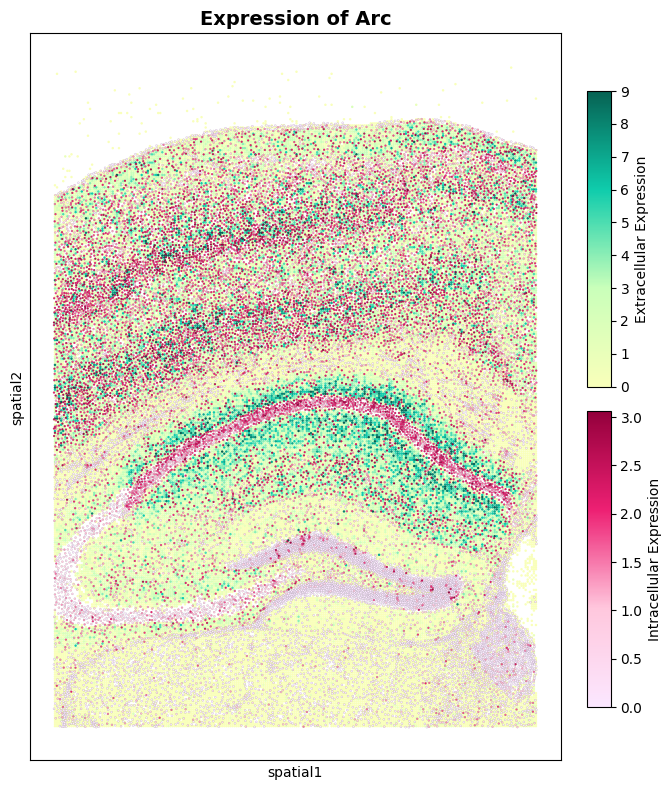

In [54]:
merged_info.sort_values(by=[metric + "_cosmx"], ascending=False)

,count_xenium,logfoldratio_over_noise_xenium,control_probe_xenium,p_value_Poisson_xenium,intracellular_proportion_xenium,extracellular_proportion_xenium,logfoldratio_extracellular_xenium,moran_I_xenium,moran_pval_norm_xenium,moran_var_norm_xenium,...,intracellular_proportion_cosmx,extracellular_proportion_cosmx,logfoldratio_extracellular_cosmx,moran_I_cosmx,moran_pval_norm_cosmx,moran_var_norm_cosmx,moran_pval_norm_fdr_bh_cosmx,in_out_spearmanR_cosmx,in_out_pvalue_cosmx,proportion_of_colocalized_cosmx
Gfap,116192,4.561323,False,0.0,0.348518,0.651482,-1.718098,0.579324,0.00000,0.000003,...,0.433500,0.566500,-1.199154,0.393795,0.000000e+00,0.000004,0.000000e+00,0.419160,0.000000e+00,0.609843
Slc17a7,322861,5.583301,False,0.0,0.762368,0.237632,0.073170,0.317081,0.00000,0.000003,...,0.679542,0.320458,-0.179901,0.237903,0.000000e+00,0.000004,0.000000e+00,0.566056,0.000000e+00,0.371283
Gad1,71568,4.076727,False,0.0,0.740499,0.259501,-0.043976,0.175084,0.00000,0.000003,...,0.755209,0.244791,0.195019,0.104917,0.000000e+00,0.000004,0.000000e+00,0.224221,1.218711e-128,0.167340
Epha4,222075,5.209094,False,0.0,0.927241,0.072759,1.452520,0.099732,0.00000,0.000003,...,0.862700,0.137300,0.906326,0.031799,0.000000e+00,0.000004,0.000000e+00,0.190786,5.115583e-93,0.092690
Sst,4499,1.309934,False,0.0,0.688375,0.311625,-0.300003,0.160720,0.00000,0.000003,...,0.643043,0.356957,-0.342974,0.292415,0.000000e+00,0.000004,0.000000e+00,0.149340,2.596411e-57,0.220967
Gad2,36282,3.397401,False,0.0,0.761755,0.238245,0.069789,0.185819,0.00000,0.000003,...,0.772185,0.227815,0.289119,0.076219,0.000000e+00,0.000004,0.000000e+00,0.192570,9.230044e-95,0.148359
Penk,20050,2.804308,False,0.0,0.815511,0.184489,0.393689,0.134156,0.00000,0.000003,...,0.852198,0.147802,0.820379,0.138887,0.000000e+00,0.000004,0.000000e+00,0.191945,3.787504e-94,0.247981
Aqp4,77426,4.155402,False,0.0,0.595007,0.404993,-0.707835,0.226598,0.00000,0.000003,...,0.731114,0.268886,0.068710,0.035430,0.000000e+00,0.000004,0.000000e+00,0.084896,1.626852e-19,0.095644
Rasgrf2,73276,4.100312,False,0.0,0.840725,0.159275,0.571098,0.235475,0.00000,0.000003,...,0.858097,0.141903,0.868007,0.036539,0.000000e+00,0.000004,0.000000e+00,0.172155,7.848326e-76,0.083589
Pvalb,45916,3.632893,False,0.0,0.710210,0.289790,-0.196134,0.228999,0.00000,0.000003,...,0.662789,0.337211,-0.255823,0.134303,0.000000e+00,0.000004,0.000000e+00,0.220996,6.249950e-125,0.205423


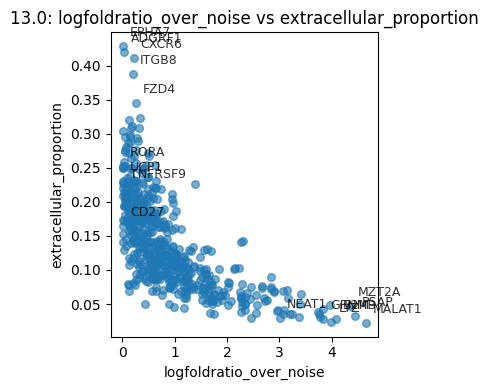

In [31]:
fig, ax = annotate_top_bottom(
    df=results,
    metric1="logfoldratio_over_noise",
    metric2="extracellular_proportion",
    n=5,
    scatter_kwargs={"alpha": 0.6, "s": 30},
    annotate_kwargs={"fontsize": 9, "color": "black"},
    title_tag=g,
    figsize=(4, 4),
)
plt.show()

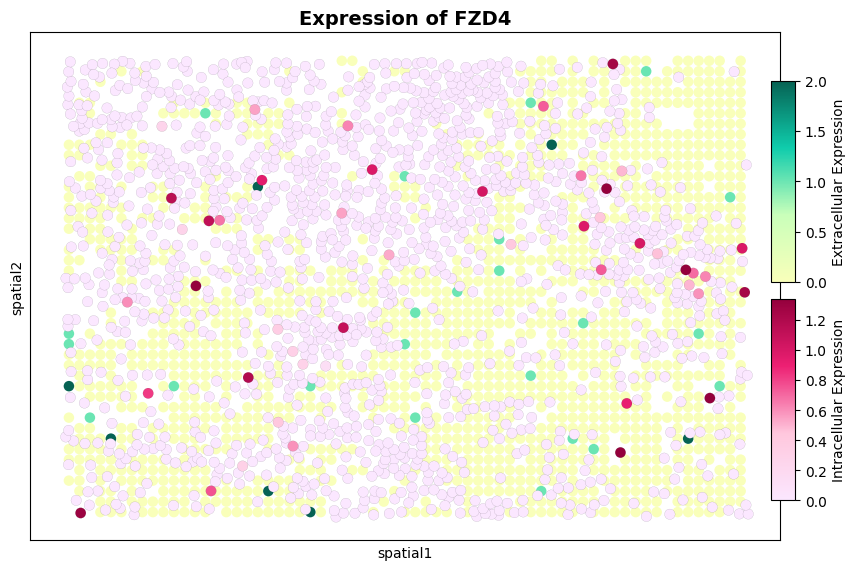

In [39]:
g2 = "FZD4"
troutpy.pl.spatial_inout_expression(sdata, g2, spot_size_cells=10, spot_size_extra=10)

In [24]:
trans = sdata["transcripts"].compute()

In [25]:
trans["segstatus"] = trans["overlaps_cell"].astype(str) + "_" + trans["extracellular"].astype(str)
stat2lab = {"True_False": "cell", "False_True": "extracellular", "False_False": "cell-like"}

In [26]:
trans["type"] = trans["segstatus"].map(stat2lab)

In [29]:
trans2 = trans.loc[:, ["x", "y", "gene", "type"]]

In [30]:
trans2.to_csv("/media/sergio/Meninges/trans2.csv")